# The Crazyflie 2.0 — flight dynamics you can **differentiate** and **`vmap`**

A 27-gram nano-quadrotor whose physics is *pure differentiable JAX*. In this
notebook we

1. load the Crazyflie from the **jaxterity** robot zoo,
2. confirm its lumped **thrust + moment wrench** model against hand physics,
3. **autodiff** the dynamics to read off the linearized $A, B$ matrices an
   LQR/MPC would use,
4. **`vmap`** a 64-drone swarm through *one* jitted controller, and
5. design a small PD controller and fly a **take-off → figure-8** trajectory,
   rendered with the real meshes.

### Where this sits in the stack

```
jaxonomy  ──▶  jaxterity  ──▶  jaxility
(JAX sim       (robots, MJX     (deploy to
 engine)        dynamics)        silicon)
```

**jaxonomy** is the JAX simulation engine. **jaxterity** (this library) adds the
robotics layer: a robot zoo, MJX-backed *differentiable* articulated dynamics,
calibrated actuator/sensor models, and a layered policy API. **jaxility** cross-
compiles a calibrated model to an embedded target.

The idea that makes this interesting: **the same calibrated JAX model is
differentiable, `jit`/`vmap`-able, *and* is the artifact that gets deployed.**
There is no separate "sim model" and "deploy model" to drift apart — you autodiff
the very dynamics that fly on the STM32. That is what we exercise below.

In [1]:
import os
import sys

# Run from the repo root so `examples` resolves as a package and the media path
# (examples/media/...) is consistent whether the kernel starts in examples/.
if os.path.basename(os.getcwd()) == "examples":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import examples._robot_render as R
from jaxterity import zoo

jax.config.update("jax_enable_x64", True)  # tidy linearization numbers
np.set_printoptions(precision=3, suppress=True)
print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.9.2 | devices: [CpuDevice(id=0)]


## 2. Load the Crazyflie — a single free body driven by a wrench

A quadrotor is the simplest interesting flyer: **one rigid body** on a 6-DoF
floating base. The configuration is

$$q = [\,x,\,y,\,z,\;q_w,\,q_x,\,q_y,\,q_z\,] \in \mathbb{R}^7,
\qquad \dot q \;\leftrightarrow\; \nu = [\,v_{\text{world}},\,\omega_{\text{body}}\,]\in\mathbb{R}^6,$$

position plus a unit quaternion ($n_q=7$), with body twist $\nu$ ($n_v=6$).

The four rotors don't appear individually — they're lumped into a **body
wrench**

$$u = [\,T,\;M_x,\,M_y,\,M_z\,],\qquad T\ \text{[N]},\ \ M\ \text{[N·m]},$$

a collective thrust $T$ along **body** $+z$ and three body moments. jaxterity maps
this wrench to the floating base's generalized force. The thrust must first be
rotated into the world frame by the current attitude $R(q)$, while the moments
are already in the body frame (the free joint's rotational coordinate):

$$Q \;=\; \big[\,T\,\hat z_{\text{body}}^{\text{world}}\;;\;\; M\,\big]
\in \mathbb{R}^6,\qquad
\hat z_{\text{body}}^{\text{world}} = R(q)\,\hat z
= \begin{bmatrix} 2(q_x q_z + q_w q_y)\\ 2(q_y q_z - q_w q_x)\\ 1-2(q_x^2+q_y^2)\end{bmatrix}.$$

`zoo.crazyflie.thrust_dynamics()` composes that wrench map with the MJX
continuous-time dynamics and hands us a pure function `f(state, u) -> dstate`.

In [2]:
drone = zoo.load("crazyflie")
f = zoo.crazyflie.thrust_dynamics()  # f(state, u) -> dstate, jit/vmap-able
MASS, G = zoo.crazyflie.MASS, 9.81

print(f"Crazyflie 2.0: mass = {MASS * 1e3:.0f} g,  weight = {MASS * G * 1e3:.1f} mN")
print("hover wrench u = [T, Mx, My, Mz] =", np.array(zoo.crazyflie.hover_control()))


# State layout: state = concat([q(7), qd(6)]); a level hover at 1 m.
def state(p=(0, 0, 1.0), quat=(1.0, 0, 0, 0), v=(0, 0, 0), w=(0, 0, 0)):
    return jnp.concatenate([jnp.array(p), jnp.array(quat), jnp.array(v), jnp.array(w)])


s_hover = state()
print("state length:", s_hover.shape[0], " (q: 7,  qd: 6)")

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


Crazyflie 2.0: mass = 27 g,  weight = 264.9 mN
hover wrench u = [T, Mx, My, Mz] = [0.265 0.    0.    0.   ]
state length: 13  (q: 7,  qd: 6)


A first look at the vehicle (rendered through the full mesh model — MuJoCo does
*kinematics only* here; all the physics ran on jaxterity's differentiable plant):

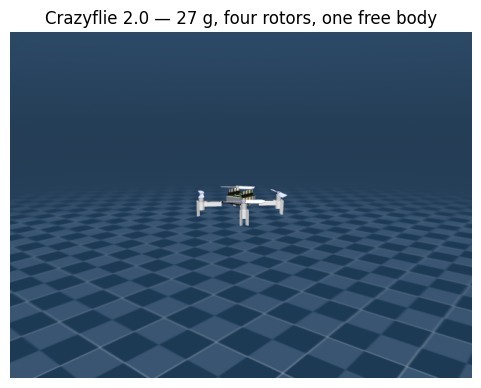

In [3]:
_ren_still = R.TrajectoryRenderer("crazyflie_mjcf", drone.to_mjcf(), size=(640, 480))
_still = _ren_still.render(
    np.array(s_hover[:7])[None, :],
    camera={"distance": 0.5, "azimuth": 130, "elevation": -12, "lookat": [0, 0, 1.0]},
    track_body="cf2",
)[0]
plt.figure(figsize=(6, 4.5))
plt.imshow(_still)
plt.axis("off")
plt.title("Crazyflie 2.0 — 27 g, four rotors, one free body")
plt.show()

## 3. Sanity-check the physics

Three predictions we can make by hand, then read off `f`:

| condition | prediction |
|---|---|
| hover wrench $T=mg$, level | vertical accel $\approx 0$ |
| zero thrust | free fall, $\ddot z = -g$ |
| tilt by $\theta$ about body-$x$, hold $T=mg$ | lateral accel $g\sin\theta$ |

The third is the key coupling: thrust always points along **body** $+z$, so
tilting the body tips the thrust vector and spills a horizontal component
$mg\sin\theta$ — this is *how a quadrotor translates*. The continuous dynamics
return $\dot{\text{state}}$; the linear acceleration is `dstate[7:10]`.

In [4]:
u_hover = zoo.crazyflie.hover_control()

a_hover = f(s_hover, u_hover)[7:10]
a_free = f(s_hover, jnp.zeros(4))[7:10]
print("hover, level     -> linear accel:", np.array(a_hover), " (expect ~0)")
print("zero thrust      -> linear accel:", np.array(a_free), f" (expect [0,0,{-G}])")


# Tilt sweep about body-x: quaternion (cos t/2, sin t/2, 0, 0).
def tilted(theta):
    q = jnp.array(
        [0, 0, 1.0, jnp.cos(theta / 2), jnp.sin(theta / 2), 0.0, 0.0, 0, 0, 0, 0, 0, 0]
    )
    return f(q, u_hover)[7:10]


thetas = jnp.linspace(0.0, 0.6, 25)
a_lat = jax.vmap(tilted)(thetas)
a_horiz = np.linalg.norm(np.array(a_lat)[:, :2], axis=1)

hover, level     -> linear accel: [0. 0. 0.]  (expect ~0)
zero thrust      -> linear accel: [ 0.    0.   -9.81]  (expect [0,0,-9.81])


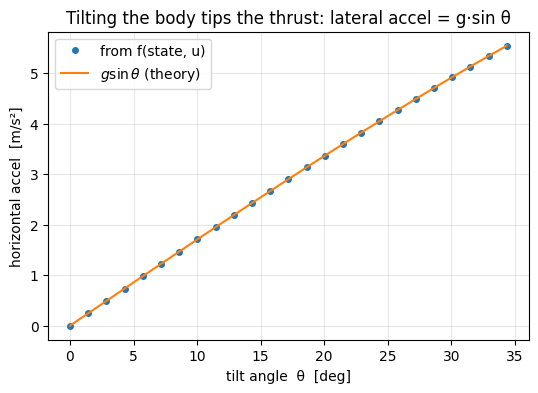

max |measured - theory| = 1.7763568394002505e-15 m/s²


In [5]:
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.plot(np.degrees(thetas), a_horiz, "o", ms=4, label="from f(state, u)")
ax.plot(
    np.degrees(thetas),
    G * np.sin(np.array(thetas)),
    "-",
    label=r"$g\sin\theta$ (theory)",
)
ax.set_xlabel("tilt angle  θ  [deg]")
ax.set_ylabel("horizontal accel  [m/s²]")
ax.set_title("Tilting the body tips the thrust: lateral accel = g·sin θ")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print(
    "max |measured - theory| =",
    float(np.max(np.abs(a_horiz - G * np.sin(np.array(thetas))))),
    "m/s²",
)

## 4. Autodiff the dynamics → the linearized flight model $A, B$

Because `f` is plain JAX, `jax.jacobian` gives us the Jacobians of $\dot s = f(s, u)$
at *any* operating point. Linearizing about hover ($s_0$, $u_0=[mg,0,0,0]$):

$$\dot{\delta s} \approx A\,\delta s + B\,\delta u,\qquad
A = \left.\frac{\partial f}{\partial s}\right|_{s_0,u_0}\in\mathbb{R}^{13\times13},\quad
B = \left.\frac{\partial f}{\partial u}\right|_{s_0,u_0}\in\mathbb{R}^{13\times4}.$$

This $(A, B)$ is exactly what an **LQR** or **MPC** consumes. jaxterity doesn't
ship a hand-derived Jacobian — it hands you the *one* differentiable model, and
you get $A, B$ by autodiff. Whatever you deploy, you linearized.

In [6]:
A = jax.jacobian(f, argnums=0)(s_hover, u_hover)  # (13, 13)
B = jax.jacobian(f, argnums=1)(s_hover, u_hover)  # (13, 4)
A, B = np.array(A), np.array(B)
print("A shape", A.shape, "  B shape", B.shape)

# Sanity-check a few structural entries.
# (i) Position kinematics: d(x)/d(vx) = 1  ->  A[0, 7].
print("A[x, vx]        =", round(A[0, 7], 3), " (expect 1: ẋ = vₓ)")
# (ii) Vertical thrust authority: d(z̈)/d(T) = 1/m  ->  B[9, 0].
print("B[z̈,  T]        =", round(B[9, 0], 3), f" (expect 1/m = {1 / MASS:.2f})")
# (iii) Gravity has no state-dependence at level hover -> A row for z̈ ~ 0.
print(
    "‖A[z̈, :]‖       =",
    round(float(np.linalg.norm(A[9])), 4),
    " (≈0: vertical accel flat at level hover)",
)

A shape (13, 13)   B shape (13, 4)
A[x, vx]        = 1.0  (expect 1: ẋ = vₓ)
B[z̈,  T]        = 37.037  (expect 1/m = 37.04)
‖A[z̈, :]‖       = 0.0  (≈0: vertical accel flat at level hover)


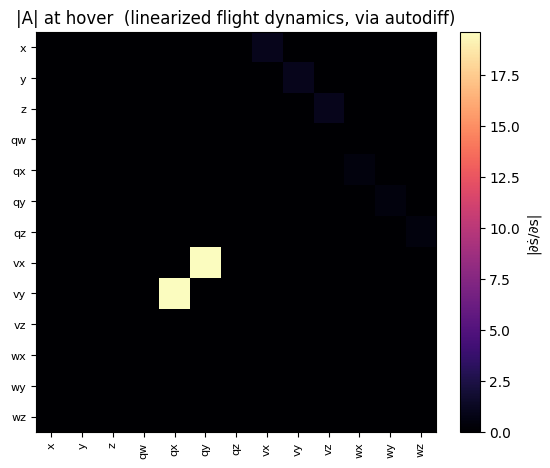

In [7]:
# A compact picture of the coupling structure (which states drive which rates).
fig, ax = plt.subplots(figsize=(6, 5.2))
im = ax.imshow(np.abs(A), cmap="magma", aspect="equal")
labels = ["x", "y", "z", "qw", "qx", "qy", "qz", "vx", "vy", "vz", "wx", "wy", "wz"]
ax.set_xticks(range(13))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticks(range(13))
ax.set_yticklabels(labels, fontsize=8)
ax.set_title("|A| at hover  (linearized flight dynamics, via autodiff)")
fig.colorbar(im, ax=ax, fraction=0.046, label="|∂ṡ/∂s|")
plt.show()

## 5. `vmap` a swarm — 64 drones through *one* jitted rollout

The payoff of pure-functional dynamics: a closed-loop rollout (controller +
RK4 integrator) is itself a pure function, so we `vmap` it over a batch of
randomized initial states and `jit` the whole thing. No Python loop over drones,
no per-drone model — one compiled kernel flies the swarm.

We use a fixed-step **RK4** integrator over `f`, and a minimal position+attitude
PD controller that emits the wrench $u$. Each drone starts from a random position
and small random tilt, all commanded to hover at the same point.

In [8]:
DT = 0.005  # 5 ms integrator step


def rk4(s, u):
    k1 = f(s, u)
    k2 = f(s + 0.5 * DT * k1, u)
    k3 = f(s + 0.5 * DT * k2, u)
    k4 = f(s + DT * k3, u)
    return s + DT / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)


def body_z_world(quat):
    w, x, y, z = quat
    return jnp.array(
        [2 * (x * z + w * y), 2 * (y * z - w * x), 1 - 2 * (x * x + y * y)]
    )


def pd_wrench(s, p_ref, v_ref, *, kp=7.0, kd=4.5, katt=0.02, kw=0.006):
    # World-frame position PD -> desired accel -> thrust + attitude PD.
    p, quat, v, w = s[0:3], s[3:7], s[7:10], s[10:13]
    a_des = kp * (p_ref - p) + kd * (v_ref - v) + jnp.array([0.0, 0.0, G])
    zb = body_z_world(quat)
    T = MASS * jnp.dot(a_des, zb)  # thrust = m · (a_des · ẑ_body)
    a_hat = a_des / jnp.linalg.norm(a_des)
    e_att = jnp.cross(zb, a_hat)  # axis aligning body-z with a_des
    M = katt * e_att - kw * w  # attitude + rate damping
    u = jnp.array([T, M[0], M[1], M[2]])
    return u.at[0].set(jnp.clip(u[0], 0.0, 0.33))  # thrust saturation [N]

In [9]:
import time

N, STEPS = 64, 600
P_REF = jnp.array([0.0, 0.0, 1.0])  # everyone -> hover at 1 m


@jax.jit
def fly_swarm(s0_batch):
    def one(s0):
        def step(s, _):
            u = pd_wrench(s, P_REF, jnp.zeros(3))
            s2 = rk4(s, u)
            return s2, s2[0:3]  # log position

        _, traj = jax.lax.scan(step, s0, None, length=STEPS)
        return traj  # (STEPS, 3)

    return jax.vmap(one)(s0_batch)  # (N, STEPS, 3)


# Randomized initial states: scattered positions + small random tilt.
key = jax.random.PRNGKey(0)
k1, k2 = jax.random.split(key)
p0 = jax.random.uniform(
    k1, (N, 3), minval=jnp.array([-0.6, -0.6, 0.4]), maxval=jnp.array([0.6, 0.6, 1.6])
)
ang = jax.random.uniform(k2, (N,), minval=-0.25, maxval=0.25)
quat0 = jnp.stack(
    [jnp.cos(ang / 2), jnp.sin(ang / 2), jnp.zeros(N), jnp.zeros(N)], axis=1
)
s0_batch = jnp.concatenate([p0, quat0, jnp.zeros((N, 6))], axis=1)

t0 = time.time()
trajs = fly_swarm(s0_batch)
trajs.block_until_ready()
trajs = np.array(trajs)
print(
    f"{N} drones × {STEPS} steps in one jitted vmap: {time.time() - t0:.2f}s "
    f"(incl. compile)"
)
final_err = np.linalg.norm(trajs[:, -1, :] - np.array(P_REF), axis=1)
print(f"mean final distance to hover point: {final_err.mean() * 100:.1f} cm")

64 drones × 600 steps in one jitted vmap: 1.64s (incl. compile)
mean final distance to hover point: 2.6 cm


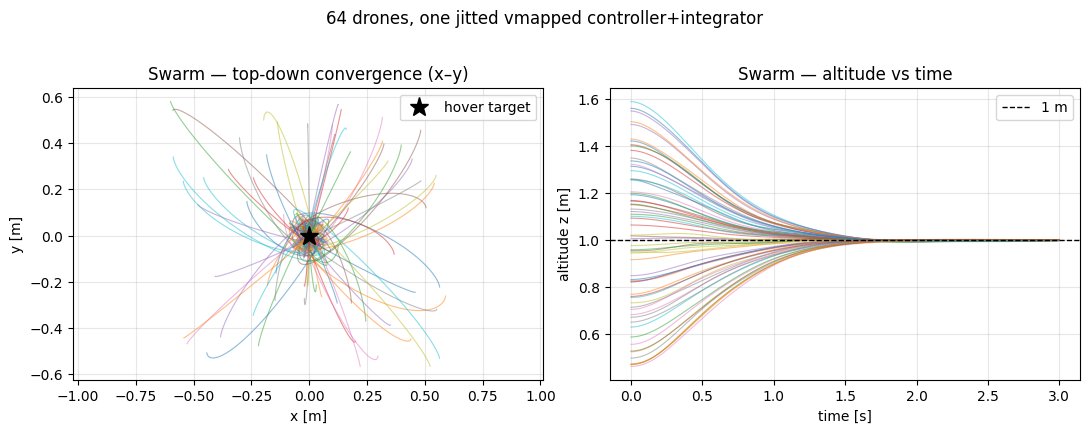

In [10]:
fig, (axxy, axz) = plt.subplots(1, 2, figsize=(11, 4.2))
for i in range(N):
    axxy.plot(trajs[i, :, 0], trajs[i, :, 1], lw=0.8, alpha=0.5)
axxy.plot(0, 0, "k*", ms=14, label="hover target")
axxy.set_xlabel("x [m]")
axxy.set_ylabel("y [m]")
axxy.axis("equal")
axxy.set_title("Swarm — top-down convergence (x–y)")
axxy.legend()
axxy.grid(alpha=0.3)

t = np.arange(STEPS) * DT
for i in range(N):
    axz.plot(t, trajs[i, :, 2], lw=0.8, alpha=0.5)
axz.axhline(1.0, color="k", ls="--", lw=1, label="1 m")
axz.set_xlabel("time [s]")
axz.set_ylabel("altitude z [m]")
axz.set_title("Swarm — altitude vs time")
axz.legend()
axz.grid(alpha=0.3)
plt.suptitle("64 drones, one jitted vmapped controller+integrator", y=1.02)
plt.tight_layout()
plt.show()

## 6. The showcase flight — take-off, then a figure-8

Same controller, now tracking a moving reference: ease up to 1 m, then trace a
horizontal **figure-8** ($x = A\sin\omega t$, $y = A\sin 2\omega t$) eased in over
the first few seconds so the take-off is gentle. We add a **velocity
feedforward** $v_{\text{ref}} = \dot p_{\text{ref}}$ (obtained — naturally — by
`jax.jacfwd` of the reference) so the drone leads the curve instead of lagging it.

In [11]:
A_FIG, PERIOD, HERO_STEPS = 0.5, 8.0, 1400  # 7 s flight at 5 ms


def p_ref(tt):
    ramp = jnp.clip(tt / 3.0, 0.0, 1.0)  # ease the figure-8 in
    z = jnp.clip(tt / 2.0, 0.0, 1.0)  # ease the take-off in
    return jnp.array(
        [
            ramp * A_FIG * jnp.sin(2 * jnp.pi * tt / PERIOD),
            ramp * A_FIG * jnp.sin(4 * jnp.pi * tt / PERIOD),
            z,
        ]
    )


v_ref = jax.jacfwd(p_ref)  # velocity feedforward, by autodiff


@jax.jit
def fly_showcase(s0):
    def step(s, k):
        tt = k * DT
        u = pd_wrench(s, p_ref(tt), v_ref(tt))
        s2 = rk4(s, u)
        err = jnp.linalg.norm(s2[0:3] - p_ref(tt))
        return s2, (s2, u, err, p_ref(tt))

    _, (traj, us, errs, refs) = jax.lax.scan(step, s0, jnp.arange(HERO_STEPS))
    return traj, us, errs, refs


s0 = state(p=(0, 0, 0.05))
traj, us, errs, refs = fly_showcase(s0)
traj, us, errs, refs = map(np.array, (traj, us, errs, refs))
print("peak tracking error :", f"{errs.max() * 100:.1f} cm")
print("final tracking error:", f"{errs[-1] * 100:.1f} cm")
print(
    "thrust range [N]    :",
    round(us[:, 0].min(), 3),
    "→",
    round(us[:, 0].max(), 3),
    "  (rotor envelope 0..0.35 N)",
)

peak tracking error : 25.0 cm
final tracking error: 16.8 cm
thrust range [N]    : 0.205 → 0.316   (rotor envelope 0..0.35 N)


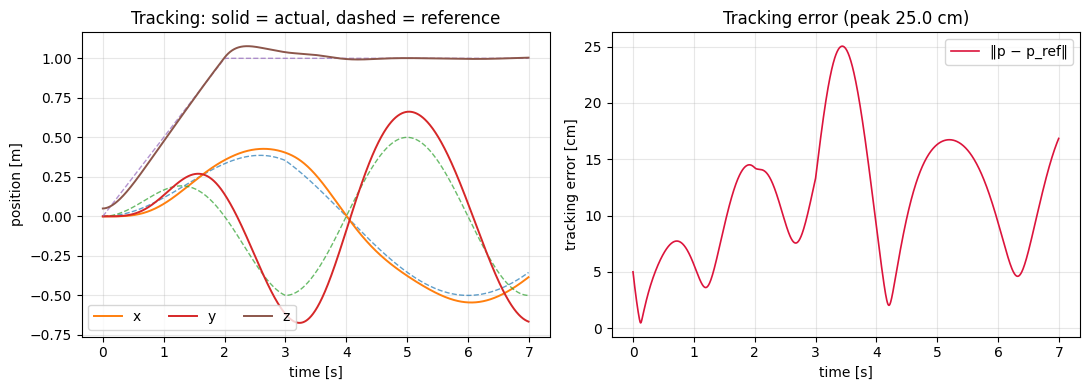

In [12]:
fig, (axt, axe) = plt.subplots(1, 2, figsize=(11, 4))
t = np.arange(HERO_STEPS) * DT
for j, lab in zip(range(3), ["x", "y", "z"]):
    axt.plot(t, refs[:, j], "--", lw=1, alpha=0.7)
    axt.plot(t, traj[:, j], lw=1.4, label=f"{lab}")
axt.set_xlabel("time [s]")
axt.set_ylabel("position [m]")
axt.set_title("Tracking: solid = actual, dashed = reference")
axt.legend(ncol=3)
axt.grid(alpha=0.3)

axe.plot(t, errs * 100, color="crimson", lw=1.2, label="‖p − p_ref‖")
axe.set_xlabel("time [s]")
axe.set_ylabel("tracking error [cm]")
axe.set_title(f"Tracking error (peak {errs.max() * 100:.1f} cm)")
axe.grid(alpha=0.3)
axe.legend()
plt.tight_layout()
plt.show()

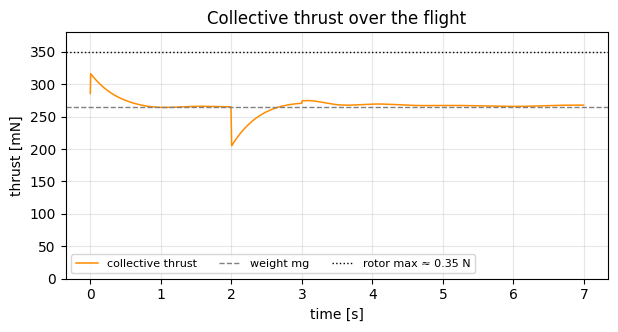

thrust stays within 0..0.35 N: True, min 0.205 N, max 0.316 N


In [13]:
# Thrust stays comfortably inside the rotor envelope (no saturation, no chatter).
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(t, us[:, 0] * 1e3, lw=1.1, color="darkorange", label="collective thrust")
ax.axhline(MASS * G * 1e3, color="gray", ls="--", lw=1, label="weight mg")
ax.axhline(0.35 * 1e3, color="k", ls=":", lw=1, label="rotor max ≈ 0.35 N")
ax.set_xlabel("time [s]")
ax.set_ylabel("thrust [mN]")
ax.set_ylim(0, 380)
ax.set_title("Collective thrust over the flight")
ax.legend(ncol=3, fontsize=8)
ax.grid(alpha=0.3)
plt.show()
print(
    f"thrust stays within 0..0.35 N: {bool((us[:, 0] <= 0.35).all())}, "
    f"min {us[:, 0].min():.3f} N, max {us[:, 0].max():.3f} N"
)

### Render it

We render `qpos(t) = state[:7]` through the full-mesh menagerie scene (kinematics
only) with the camera tracking the `cf2` body, and overlay a thrust arrow along
body $+z$ scaled by $T$.

In [14]:
GIF_PATH = "examples/media/tutorial_crazyflie.gif"
STRIDE = 14  # 1400 -> 100 frames (≤5 MB)

ren = R.TrajectoryRenderer("crazyflie_mjcf", drone.to_mjcf(), size=(720, 540))
qpos_traj = traj[:, :7]

# Per-frame thrust arrow: body +z scaled by T/T_max.
_thr = us[::STRIDE, 0]


def make_overlay(thr_seq):
    i = {"k": 0}

    def overlay(scene, data, q):
        k = min(i["k"], len(thr_seq) - 1)
        T = thr_seq[k]
        p, zb = q[0:3], body_z_world(jnp.array(q[3:7]))
        R.add_arrow(
            scene,
            p,
            p + np.array(zb) * (T / 0.35) * 0.28,
            rgba=(0.95, 0.35, 0.1, 1.0),
            width=0.008,
        )
        i["k"] += 1

    return overlay


frames = ren.render(
    qpos_traj,
    stride=STRIDE,
    camera={"distance": 0.85, "azimuth": 130, "elevation": -14, "lookat": [0, 0, 1.0]},
    track_body="cf2",
    overlay=make_overlay(_thr),
)
R.write_gif(frames, GIF_PATH, width=420, fps=20)
_mb = os.path.getsize(GIF_PATH) / 1e6
print("wrote", GIF_PATH, "| frames:", len(frames), f"| {_mb:.1f} MB")

wrote examples/media/tutorial_crazyflie.gif | frames: 100 | 4.0 MB


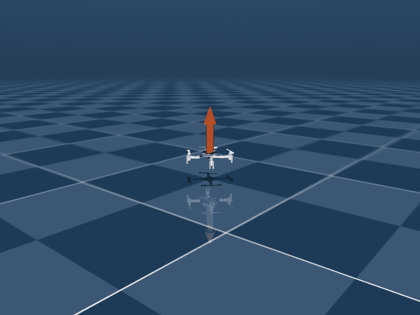

In [15]:
from IPython.display import Image

Image(GIF_PATH)

The drone eases up to 1 m, then carves a smooth figure-8 while staying upright;
the orange arrow is the collective thrust, tipping with the body as it banks into
each turn — exactly the $g\sin\theta$ coupling from §3, now closing the loop.

## 7. Exercises & takeaways

**Exercises**

1. **LQR from the autodiffed model.** Take the $(A, B)$ from §4 and design an LQR
   gain $K$ (e.g. with `jax.scipy` / a Riccati solve or `jaxonomy`'s LQR block).
   Replace `pd_wrench` with $u = u_0 - K(s - s_0)$ and compare hover convergence.
2. **A bigger, faster figure-8.** Push `A_FIG` to 1.0 m and halve `PERIOD`. Watch
   the peak tracking error and the thrust trace — where does the rotor envelope
   (0.35 N) start to saturate, and how does the flight degrade?
3. **Differentiate through the rollout.** `fly_showcase` is pure JAX, so
   `jax.grad` of the mean tracking error w.r.t. the controller gains
   (`kp, kd, katt, kw`) exists. Autotune the gains by gradient descent — a tiny
   taste of differentiable control.

**Takeaways**

- A quadrotor is a single free body ($n_q=7$, $n_v=6$); rotors enter as a lumped
  **wrench** $u=[T, M_x, M_y, M_z]$ that jaxterity maps to the base generalized
  force, rotating thrust into the world by the attitude.
- The flight dynamics `f(state, u)` are **pure differentiable JAX**:
  `jax.jacobian` gives the linearized $A, B$ for LQR/MPC, `vmap` flies a swarm in
  one jitted kernel, and `jax.grad` reaches through a whole rollout.
- This is the **payoff**: the differentiable, batchable model you design
  and tune *here* is the same calibrated model **jaxility** deploys to the STM32 —
  no sim-to-deploy drift.